# Week 2 Lab: From Tokens to a Tiny GPT and LLaMA Components

This notebook is the practical companion to Week 2 of **Deep Learning in 100 Hours**. It builds the decoder-only path in small, testable pieces and uses generated text only. It is a teaching implementation, not an official GPT or LLaMA reproduction.

| Day | Main idea | Evidence to keep |
|---|---|---|
| 6 | Tokenization, embeddings, next-token targets | Reversible encoding and shifted examples |
| 7 | Scaled dot-product and multi-head attention | Future and padded-key probabilities are zero |
| 8 | Pre-norm Transformer block | Shape and gradient paths remain valid |
| 9 | Tiny GPT training and generation | Loss falls and sampling controls work |
| 10 | RMSNorm, RoPE, and SwiGLU | Component-level mathematical tests pass |

Run the notebook from a fresh kernel before modifying it. Use **Python 3.11 (dl100h)**. All required work is CPU-friendly and offline.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader

from dl100h.attention import CausalSelfAttention
from dl100h.data import CharTokenizer, NextTokenDataset
from dl100h.llama_parts import RMSNorm, SwiGLU, apply_rope
from dl100h.tiny_gpt import Block, GPTConfig, TinyGPT
from dl100h.utils import count_parameters, seed_everything

seed_everything(42)
device = torch.device('cpu')
print({'torch': torch.__version__, 'device': str(device)})

{'torch': '2.5.1', 'device': 'cpu'}


# Day 6 — Tokenization, embeddings, and next-token examples

A tokenizer maps text to integer IDs; an embedding table maps each ID to a learned vector. Character tokenization is inefficient for real language models, but it makes every step visible and requires no external files.

For autoregressive training, an input window $(x_0,\ldots,x_{T-1})$ is paired with the shifted target $(x_1,\ldots,x_T)$. One forward pass predicts all $T$ targets in parallel, although generation later produces one token at a time.

In [2]:
corpus = 'attention selects useful context. transformer predicts the next token. ' * 30
tokenizer = CharTokenizer.from_text(corpus)
encoded = tokenizer.encode(corpus)
decoded = tokenizer.decode(encoded)

assert decoded == corpus
assert min(encoded) >= 0 and max(encoded) < tokenizer.vocab_size
{
    'characters': len(corpus),
    'vocabulary_size': tokenizer.vocab_size,
    'first_24_ids': encoded[:24],
    'round_trip': decoded == corpus,
}

{'characters': 2130,
 'vocabulary_size': 20,
 'first_24_ids': [2,
  17,
  17,
  5,
  12,
  17,
  8,
  13,
  12,
  0,
  16,
  5,
  10,
  5,
  3,
  17,
  16,
  0,
  18,
  16,
  5,
  6,
  18,
  10],
 'round_trip': True}

In [3]:
block_size = 16
next_token_dataset = NextTokenDataset(encoded, block_size=block_size)
next_token_loader = DataLoader(next_token_dataset, batch_size=4, shuffle=False)
input_ids, target_ids = next(iter(next_token_loader))

assert input_ids.shape == target_ids.shape == (4, block_size)
assert torch.equal(input_ids[:, 1:], target_ids[:, :-1])
{
    'input_shape': tuple(input_ids.shape),
    'first_input': tokenizer.decode(input_ids[0].tolist()),
    'first_target': tokenizer.decode(target_ids[0].tolist()),
}

{'input_shape': (4, 16),
 'first_input': 'attention select',
 'first_target': 'ttention selects'}

In [4]:
embedding_dim = 24
embedding = nn.Embedding(tokenizer.vocab_size, embedding_dim)
embedded = embedding(input_ids)
torch.manual_seed(6)
example_logits = torch.randn(*target_ids.shape, tokenizer.vocab_size)
cross_entropy = F.cross_entropy(
    example_logits.reshape(-1, tokenizer.vocab_size), target_ids.reshape(-1)
)
manual_nll = -example_logits.log_softmax(dim=-1).gather(
    dim=-1, index=target_ids.unsqueeze(-1)
).mean()

torch.testing.assert_close(cross_entropy, manual_nll)
{
    'embedding_shape': tuple(embedded.shape),
    'embedding_parameters': count_parameters(embedding),
    'mean_negative_log_likelihood': cross_entropy.item(),
}

{'embedding_shape': (4, 16, 24),
 'embedding_parameters': 480,
 'mean_negative_log_likelihood': 3.4047279357910156}

## Day 6 practice and acceptance

1. Change the block size and predict the dataset length before running.
2. Compare character tokens with a manually defined word-level vocabulary on one sentence.
3. Compute perplexity as $\exp(\text{mean NLL})$ and explain why it is large for random logits.
4. Identify how unknown tokens, padding, and special beginning/end tokens would enter a production tokenizer.

**Accept the day when:** encoding is reversible, every ID is in range, the target is exactly shifted by one position, and you can state the shapes before and after embedding lookup.

# Day 7 — Scaled dot-product, causal, and padding attention

For one attention head,

$$A=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{D_h}}+M\right),\qquad O=AV.$$

The scale $\sqrt{D_h}$ prevents dot products from growing with head width. A **causal mask** blocks future key positions. A **padding-key mask** blocks meaningless padded keys. A separate **loss mask** decides which target positions contribute to training; the attention module does not create that loss mask for you.

In [5]:
torch.manual_seed(7)
B, T, head_dim = 2, 5, 8
query = torch.randn(B, T, head_dim)
key = torch.randn(B, T, head_dim)
value = torch.randn(B, T, head_dim)

raw_scores = query @ key.transpose(-2, -1)
scaled_scores = raw_scores / math.sqrt(head_dim)
causal_mask = torch.ones(T, T, dtype=torch.bool).tril()
masked_scores = scaled_scores.masked_fill(~causal_mask, float('-inf'))
manual_weights = masked_scores.softmax(dim=-1)
manual_output = manual_weights @ value

future_values = manual_weights.masked_select(~causal_mask)
assert torch.count_nonzero(future_values) == 0
torch.testing.assert_close(manual_weights.sum(dim=-1), torch.ones(B, T))
{
    'score_shape': tuple(scaled_scores.shape),
    'output_shape': tuple(manual_output.shape),
    'raw_score_std': raw_scores.std().item(),
    'scaled_score_std': scaled_scores.std().item(),
    'maximum_future_probability': future_values.abs().max().item(),
}

{'score_shape': (2, 5, 5),
 'output_shape': (2, 5, 8),
 'raw_score_std': 2.494964838027954,
 'scaled_score_std': 0.8821033239364624,
 'maximum_future_probability': 0.0}

In [6]:
torch.manual_seed(70)
sequence = torch.randn(2, 5, 16)
padding_key_mask = torch.tensor([
    [1, 1, 1, 1, 1],
    [1, 1, 1, 0, 0],
], dtype=torch.bool)
attention = CausalSelfAttention(dim=16, n_heads=4)
attention_output, attention_weights = attention(
    sequence, attention_mask=padding_key_mask, return_weights=True
)

future_mask = ~torch.ones(5, 5, dtype=torch.bool).tril()
future_probabilities = attention_weights.masked_select(future_mask[None, None])
padded_key_probabilities = attention_weights[1, :, :, 3:]
assert torch.count_nonzero(future_probabilities) == 0
assert torch.count_nonzero(padded_key_probabilities) == 0
torch.testing.assert_close(attention_weights.sum(dim=-1), torch.ones(2, 4, 5))
{
    'output_shape': tuple(attention_output.shape),
    'weight_shape': tuple(attention_weights.shape),
    'maximum_future_probability': future_probabilities.abs().max().item(),
    'maximum_padded_key_probability': padded_key_probabilities.abs().max().item(),
}

{'output_shape': (2, 5, 16),
 'weight_shape': (2, 4, 5, 5),
 'maximum_future_probability': 0.0,
 'maximum_padded_key_probability': 0.0}

## Day 7 practice and acceptance

1. Remove the $\sqrt{D_h}$ scale and compare score and softmax concentration as head width grows.
2. Deliberately reverse the triangular causal mask and write a test that catches the leak.
3. Explain why padded **queries** may still produce values even though padded **keys** receive zero probability.
4. Design a target loss mask that excludes padded target positions.

**Accept the day when:** you can trace $(B,H,T,D_h)$, distinguish all three masks, and prove behavior with probabilities rather than only checking shapes.

# Day 8 — A pre-norm Transformer decoder block

The block used here is

$$X' = X + \operatorname{Attention}(\operatorname{LN}(X)),$$

$$Y = X' + \operatorname{MLP}(\operatorname{LN}(X')).$$

Residual paths preserve the $(B,T,C)$ interface and provide a direct gradient route. Layer normalization acts over the channel dimension for each token. The MLP expands channels, applies a nonlinearity, and projects back.

In [7]:
seed_everything(8)
block_config = GPTConfig(vocab_size=32, block_size=8, dim=32, n_heads=4, n_layers=1)
decoder_block = Block(block_config)
block_input = torch.randn(2, 7, 32, requires_grad=True)
block_output = decoder_block(block_input)
block_objective = block_output.square().mean()
block_objective.backward()

assert block_output.shape == block_input.shape
assert block_input.grad is not None and torch.isfinite(block_input.grad).all()
{
    'input_output_shape': tuple(block_output.shape),
    'parameters': count_parameters(decoder_block),
    'input_gradient_norm': block_input.grad.norm().item(),
}

{'input_output_shape': (2, 7, 32),
 'parameters': 12704,
 'input_gradient_norm': 0.10090696811676025}

In [8]:
with torch.inference_mode():
    clean_input = block_input.detach()
    attention_branch = decoder_block.attn(decoder_block.ln1(clean_input))
    after_attention = clean_input + attention_branch
    mlp_branch = decoder_block.mlp(decoder_block.ln2(after_attention))
    reconstructed_output = after_attention + mlp_branch
    direct_output = decoder_block(clean_input)

torch.testing.assert_close(reconstructed_output, direct_output)
{
    'input_norm': clean_input.norm().item(),
    'attention_branch_norm': attention_branch.norm().item(),
    'mlp_branch_norm': mlp_branch.norm().item(),
    'reconstruction_max_error': (reconstructed_output - direct_output).abs().max().item(),
}

{'input_norm': 21.342044830322266,
 'attention_branch_norm': 5.820192337036133,
 'mlp_branch_norm': 4.255037784576416,
 'reconstruction_max_error': 0.0}

## Day 8 practice and acceptance

1. Remove one residual addition and compare input-gradient norms across several random seeds.
2. Move normalization after each residual addition to create a post-norm variant.
3. Change the MLP expansion factor from four to two and calculate the parameter reduction before running.
4. Add dropout, then demonstrate why train and eval modes differ.

**Accept the day when:** you can reconstruct the forward pass branch by branch, justify pre-norm placement, and show a finite gradient reaching the block input.

# Day 9 — Train and sample from a Tiny GPT

A decoder-only language model adds token and position embeddings, applies causal decoder blocks, normalizes the final representation, and projects it to vocabulary logits. Training predicts all positions in parallel. Generation repeatedly crops the context, runs a forward pass, and samples one new token.

This is a deliberate tiny-overfit test. A falling loss proves that data, targets, gradients, and sampling are connected; it does not prove language understanding.

In [9]:
seed_everything(9)
training_text = 'transformer attention predicts the next token. ' * 50
gpt_tokenizer = CharTokenizer.from_text(training_text)
training_ids = torch.tensor(gpt_tokenizer.encode(training_text), dtype=torch.long)
gpt_config = GPTConfig(
    vocab_size=gpt_tokenizer.vocab_size,
    block_size=32,
    dim=48,
    n_heads=4,
    n_layers=2,
    dropout=0.0,
)
tiny_gpt = TinyGPT(gpt_config).to(device)

assert tiny_gpt.lm_head.weight.data_ptr() == tiny_gpt.token_embedding.weight.data_ptr()
{
    'vocabulary_size': gpt_tokenizer.vocab_size,
    'tokens': len(training_ids),
    'parameters': count_parameters(tiny_gpt),
    'weight_tying': True,
}

{'vocabulary_size': 18,
 'tokens': 2350,
 'parameters': 59040,
 'weight_tying': True}

In [10]:
gpt_optimizer = torch.optim.AdamW(tiny_gpt.parameters(), lr=3e-3, weight_decay=1e-2)
training_generator = torch.Generator().manual_seed(9)
gpt_losses = []
maximum_start = len(training_ids) - gpt_config.block_size - 1

tiny_gpt.train()
for step in range(120):
    start = torch.randint(0, maximum_start, (1,), generator=training_generator).item()
    model_input = training_ids[start : start + gpt_config.block_size][None].to(device)
    model_target = training_ids[start + 1 : start + gpt_config.block_size + 1][None].to(device)
    _, gpt_loss = tiny_gpt(model_input, model_target)
    gpt_optimizer.zero_grad(set_to_none=True)
    gpt_loss.backward()
    torch.nn.utils.clip_grad_norm_(tiny_gpt.parameters(), max_norm=1.0)
    gpt_optimizer.step()
    gpt_losses.append(gpt_loss.item())

assert gpt_losses[-1] < gpt_losses[0]
{'initial_loss': gpt_losses[0], 'final_loss': gpt_losses[-1]}

{'initial_loss': 2.870079278945923, 'final_loss': 0.5963993072509766}

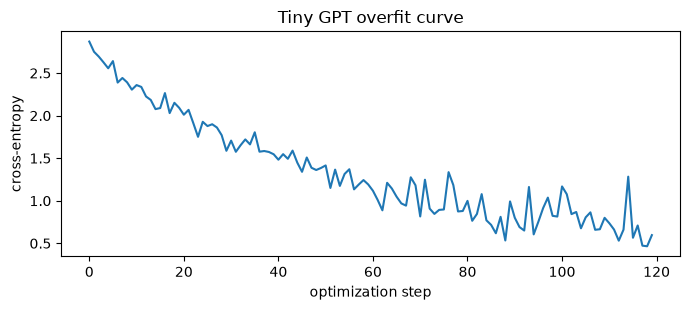

In [11]:
plt.figure(figsize=(7, 3.2))
plt.plot(gpt_losses)
plt.xlabel('optimization step')
plt.ylabel('cross-entropy')
plt.title('Tiny GPT overfit curve')
plt.tight_layout()
plt.show()

In [12]:
prompt_text = 'transformer '
prompt_ids = torch.tensor(gpt_tokenizer.encode(prompt_text), dtype=torch.long)[None]
sampling_settings = {
    'low_temperature': {'temperature': 0.5},
    'high_temperature': {'temperature': 1.2},
    'top_k': {'temperature': 0.8, 'top_k': 8},
    'top_p': {'temperature': 0.8, 'top_p': 0.90},
}
samples = {}
for name, settings in sampling_settings.items():
    torch.manual_seed(90)
    generated = tiny_gpt.generate(prompt_ids.clone(), max_new_tokens=48, **settings)
    samples[name] = gpt_tokenizer.decode(generated[0].tolist())
samples

{'low_temperature': 'transformer atenttentention predicthedicthe ts the ts the th',
 'high_temperature': 'transformer aten p pnedictonedict. t ts thenext tokerme trt ',
 'top_k': 'transformer aten predictthedicttsfore the ts ne toke nedict ',
 'top_p': 'transformer aten predictthedictts next tokenensforansformen '}

## Day 9 practice and acceptance

1. Calculate the parameter change before increasing layers from two to three.
2. Hold the random seed fixed and compare temperatures 0.5, 1.0, and 1.5.
3. Compare top-$k$ with top-$p$ and inspect how many candidate tokens survive each filter.
4. Deliberately misalign the targets and explain the new loss curve.
5. Explain why the generated sample can look plausible while memorizing a tiny repeated corpus.

**Accept the day when:** the loss falls, weight tying is verified, all four sampling routes run, and you can distinguish parallel training from sequential generation.

# Day 10 — LLaMA-style components: RMSNorm, RoPE, and SwiGLU

LLaMA remains a decoder-only causal language model, but common component choices differ from the tiny GPT above:

- RMSNorm rescales by root mean square without subtracting the mean.
- RoPE rotates adjacent query/key coordinate pairs by position-dependent angles, so attention scores encode relative displacement.
- SwiGLU multiplies a SiLU gate by a separate value projection before projecting down.

The Light Demo ends with component-level checks. Integrating RoPE inside a full attention implementation and training a large LLaMA model are optional extensions.

In [13]:
torch.manual_seed(10)
rms_input = torch.randn(2, 5, 8, dtype=torch.float64)
rms_norm = RMSNorm(8).double()
rms_output = rms_norm(rms_input)
manual_rms_output = rms_input * torch.rsqrt(
    rms_input.square().mean(dim=-1, keepdim=True) + rms_norm.eps
)

torch.testing.assert_close(rms_output, manual_rms_output)
{
    'shape': tuple(rms_output.shape),
    'input_mean': rms_input.mean().item(),
    'output_mean': rms_output.mean().item(),
    'output_mean_square': rms_output.square().mean().item(),
}

{'shape': (2, 5, 8),
 'input_mean': 0.0763003127433893,
 'output_mean': 0.11816406645230018,
 'output_mean_square': 0.9999989167136842}

In [14]:
torch.manual_seed(100)
base_query = torch.randn(1, 2, 1, 8)
base_key = torch.randn(1, 2, 1, 8)
repeated_query = base_query.repeat(1, 1, 6, 1)
repeated_key = base_key.repeat(1, 1, 6, 1)
rotated_query, rotated_key = apply_rope(repeated_query, repeated_key)

torch.testing.assert_close(rotated_query.norm(dim=-1), repeated_query.norm(dim=-1))
torch.testing.assert_close(rotated_key.norm(dim=-1), repeated_key.norm(dim=-1))
score_0_to_2 = (rotated_query[:, :, 0] * rotated_key[:, :, 2]).sum(dim=-1)
score_1_to_3 = (rotated_query[:, :, 1] * rotated_key[:, :, 3]).sum(dim=-1)
torch.testing.assert_close(score_0_to_2, score_1_to_3, rtol=1e-5, atol=1e-6)
torch.testing.assert_close(rotated_query[:, :, 0], repeated_query[:, :, 0])
{
    'shape': tuple(rotated_query.shape),
    'norm_preserved': True,
    'equal_relative_displacement_scores': True,
    'position_zero_unchanged': True,
}

{'shape': (1, 2, 6, 8),
 'norm_preserved': True,
 'equal_relative_displacement_scores': True,
 'position_zero_unchanged': True}

In [15]:
swiglu = SwiGLU(dim=32, hidden_dim=64)
swiglu_input = torch.randn(2, 5, 32, requires_grad=True)
swiglu_output = swiglu(swiglu_input)
swiglu_output.square().mean().backward()

assert swiglu_output.shape == swiglu_input.shape
assert all(parameter.grad is not None for parameter in swiglu.parameters())
{
    'input_output_shape': tuple(swiglu_output.shape),
    'parameters': count_parameters(swiglu),
    'input_gradient_norm': swiglu_input.grad.norm().item(),
}

{'input_output_shape': (2, 5, 32),
 'parameters': 6144,
 'input_gradient_norm': 0.004193094093352556}

## Day 10 practice and acceptance

1. Compare RMSNorm with LayerNorm on inputs shifted by a large constant.
2. Prove algebraically why a shared rotation preserves vector norms.
3. Repeat the RoPE score test with displacement one, two, and three.
4. Compare SwiGLU parameters with the four-times-expansion GELU MLP from Day 8.
5. Sketch exactly where RoPE must be applied inside multi-head attention: after splitting query/key heads and before their dot product.

**Accept the day when:** the three component tests pass and you can explain what changes from GPT-style components without claiming that this notebook trains a production LLaMA.

# Week 2 acceptance checklist

- [ ] I can construct shifted next-token examples and explain token, position, and target axes.
- [ ] I can derive scaled dot-product attention and trace $(B,H,T,D_h)$.
- [ ] I can distinguish causal, padding-key, and target loss masks.
- [ ] I can reconstruct a pre-norm decoder block from its two residual branches.
- [ ] I can overfit the tiny corpus and explain why that is only a pipeline check.
- [ ] I can explain temperature, top-$k$, and top-$p$ sampling.
- [ ] I can test RMSNorm, RoPE, and SwiGLU independently.
- [ ] I can describe the main component differences between this Tiny GPT and a LLaMA-style decoder.

Save the loss curve, sample comparison, mask-test evidence, and failed experiments in the experiment log. Continue to Week 3 only after this notebook runs from a fresh kernel and you can answer the checklist without reading the code.